In [1]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph

In [2]:
# We now create an AgentState - shared data structure that keeps track of information as your application runs. 

class AgentState(TypedDict): # Our state schema
    name: str

def greeting_node(state: AgentState) -> AgentState:
    """ Simple node that creates a personalized greeting and adds it to the state. """

    state["name"] = state["name"] + ", you 're doing an amazing job learning LangGraph!"

    return state

In [3]:
graph = StateGraph(AgentState)

# add node to the graph
# 1st argument: name of the node
# 2nd argument: function that defines the node's behavior
graph.add_node("compliment", greeting_node)

graph.set_entry_point("compliment")
graph.set_finish_point("compliment")

app = graph.compile()

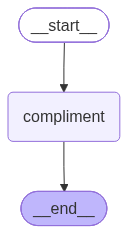

In [4]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png())) # visualize the graph

In [5]:
result = app.invoke({ "name": "Bob" })

In [6]:
result["name"]

"Bob, you 're doing an amazing job learning LangGraph!"